In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from typing_extensions import Writer

In [ ]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_file(keyword, fallback_index):
  matches = [
      name for name in uploaded_names if keyword.lower() in name.lower()
  ]

  if matches:
    return '/content/' + matches[0]

  if fallback_index < len(uploaded_names):
    return '/content/' + uploaded_names[fallback_index]
  raise FileNotFoundError(f'No File Found With Keyword "{keyword}"')

input_image_path = find_uploaded_file('green-sccreen', 0)
bg_image_path = find_uploaded_file('balloon', 1)
video_path = find_uploaded_file('akhavan-green-bg', 2)

input_image = cv2.imread(input_image_path)
bg_image = cv2.imread(bg_image_path)

print(input_image.shape)
print(bg_image.shape)

Saving akhavan-green-bg.mp4 to akhavan-green-bg.mp4
Saving balloon.png to balloon.png
Saving green-sccreen.png to green-sccreen.png
(500, 888, 3)
(278, 372, 3)


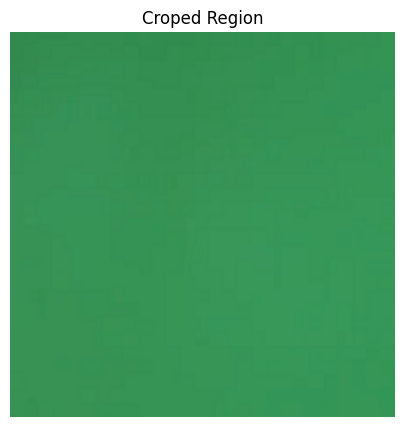

[ 70.457575 162.526525 147.248   ]


In [ ]:
croped_region = input_image[:200, :200, :]

plt.figure(figsize=(5, 5))
plt.imshow(cv2.cvtColor(croped_region, cv2.COLOR_BGR2RGB))
plt.title('Croped Region')
plt.axis('off')

plt.show()

sample_hsv = cv2.cvtColor(croped_region, cv2.COLOR_BGR2HSV)
mean_hsv = np.mean(sample_hsv, axis=(0, 1))
print(mean_hsv)

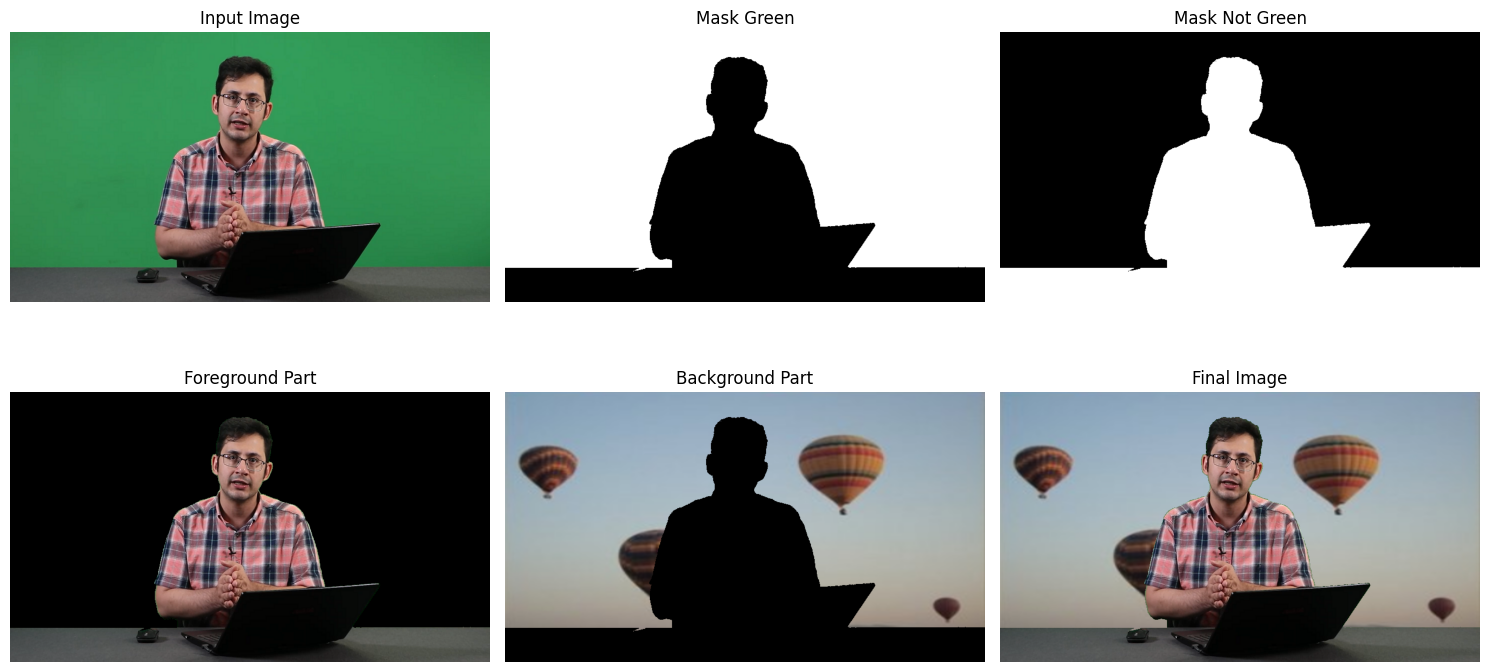

In [ ]:
height, width = input_image.shape[:2]
bg_image = cv2.resize(bg_image, (width, height))

hsv_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2HSV)
lower_green = np.array([60, 50, 50])
upper_green = np.array([80, 255, 255])
mask = cv2.inRange(hsv_image, lower_green, upper_green)

mask_not_green = cv2.bitwise_not(mask)

background = cv2.bitwise_and(bg_image, bg_image, mask=mask)
foreground = cv2.bitwise_and(input_image, input_image, mask=mask_not_green)

result = cv2.add(background, foreground)

plt.figure(figsize=(15, 8))

images = [
    input_image,
    mask,
    mask_not_green,
    foreground,
    background,
    result,
]

titles = [
    'Input Image',
    'Mask Green',
    'Mask Not Green',
    'Foreground Part',
    'Background Part',
    'Final Image',
]

for index, (image, title) in enumerate(zip(images, titles), start=1):
    plt.subplot(2, 3, index)

    if len(image.shape) == 2:
        plt.imshow(image, cmap='gray')

    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
def replace_green_background(frame, background, lower, upper, dilate=False):
  frame_height, frame_width = frame.shape[:2]
  background = cv2.resize(background, (frame_width, frame_height))

  hsv_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
  mask = cv2.inRange(hsv_frame, lower, upper)

  if dilate:
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.dilate(mask, kernel)

  mask_not_green = cv2.bitwise_not(mask)

  new_background = cv2.bitwise_and(background, background, mask=mask)
  foreground = cv2.bitwise_and(frame, frame, mask=mask_not_green)

  result = cv2.add(foreground, new_background)

  return result, mask

In [ ]:
def process_video_hsv(video_path, background_path, lower, upper, dilate=False):
  cap = cv2.VideoCapture(video_path)
  if not cap.isOpened():
    print('Error Opening Video File')

  fps = cap.get(cv2.CAP_PROP_FPS)
  if fps <= 0:
    fps = 20.0

  output_frames = []
  sample_frames = []

  while True:
    ret, frame = cap.read()

    if not ret:
      break

    result, mask = replace_green_background(frame, background_path, lower, upper, dilate)
    output_frames.append(result)

    if len(sample_frames) < 10:
      sample_frames.append((frame.copy(), mask.copy(), result.copy()))

  cap.release()
  return output_frames, sample_frames, fps

hsv_frames, hsv_sample_frames, video_fps = process_video_hsv(video_path, bg_image, lower_green, upper_green, dilate=False)

print(video_fps)

30.00958160332162


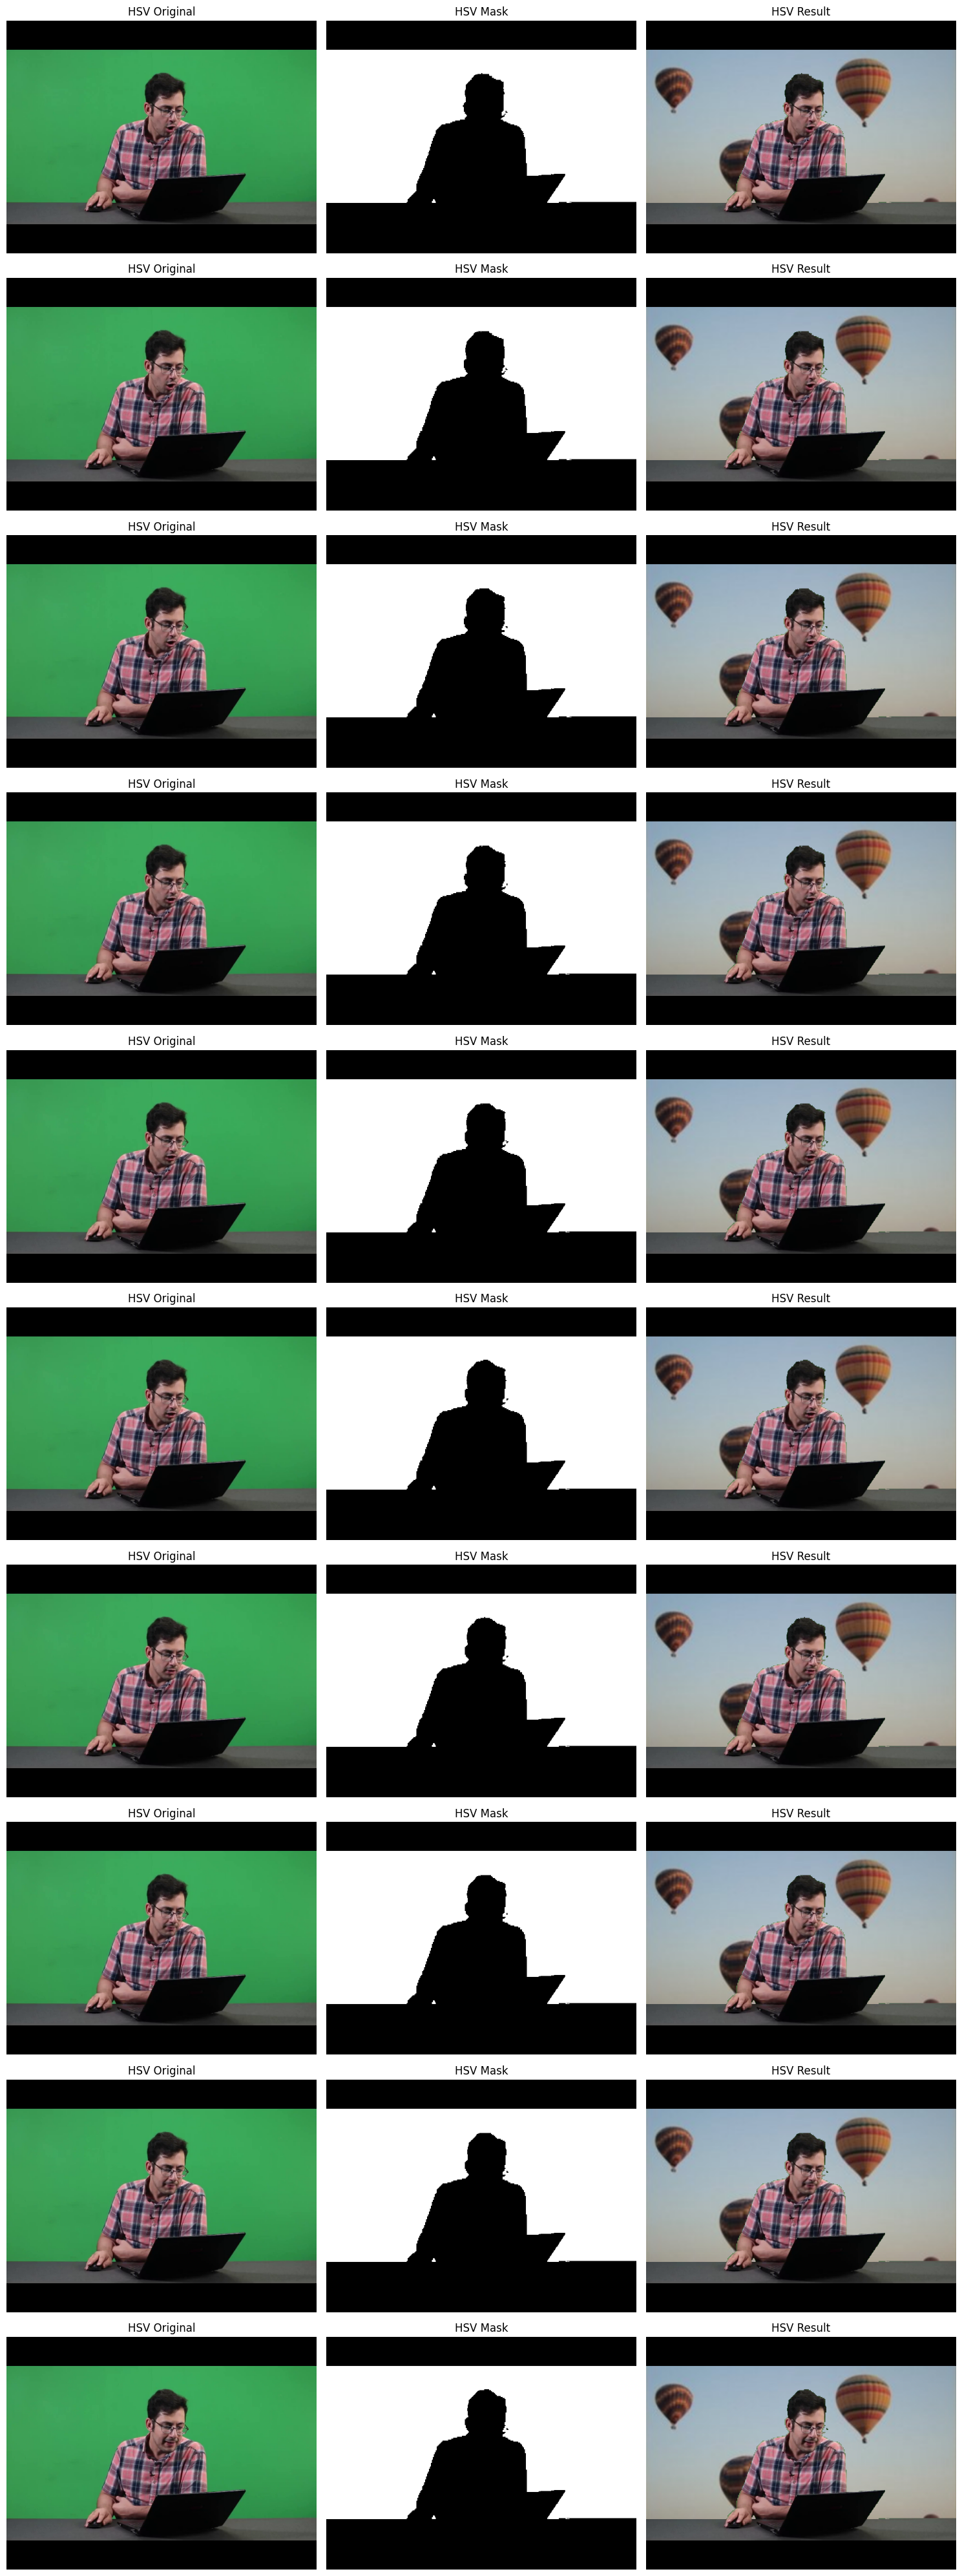

In [ ]:
def show_vide0_samples(samples, title_prefix):
  if len(samples) == 0:
    raise ValueError('No Samples Provided')

  plt.figure(figsize=(15, 4 * len(samples)))

  for index, (original, mask, result) in enumerate(samples, start=1):
    plt.subplot(len(samples), 3, 3 * index - 2)
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.title(f'{title_prefix} Original')
    plt.axis('off')

    plt.subplot(len(samples), 3, 3 * index - 1)
    plt.imshow(mask, cmap='gray')
    plt.title(f'{title_prefix} Mask')
    plt.axis('off')

    plt.subplot(len(samples), 3, 3 * index)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f'{title_prefix} Result')
    plt.axis('off')

  plt.tight_layout()
  plt.show()

show_vide0_samples(hsv_sample_frames, 'HSV')

HSV + Dilation Processed Frames: 261


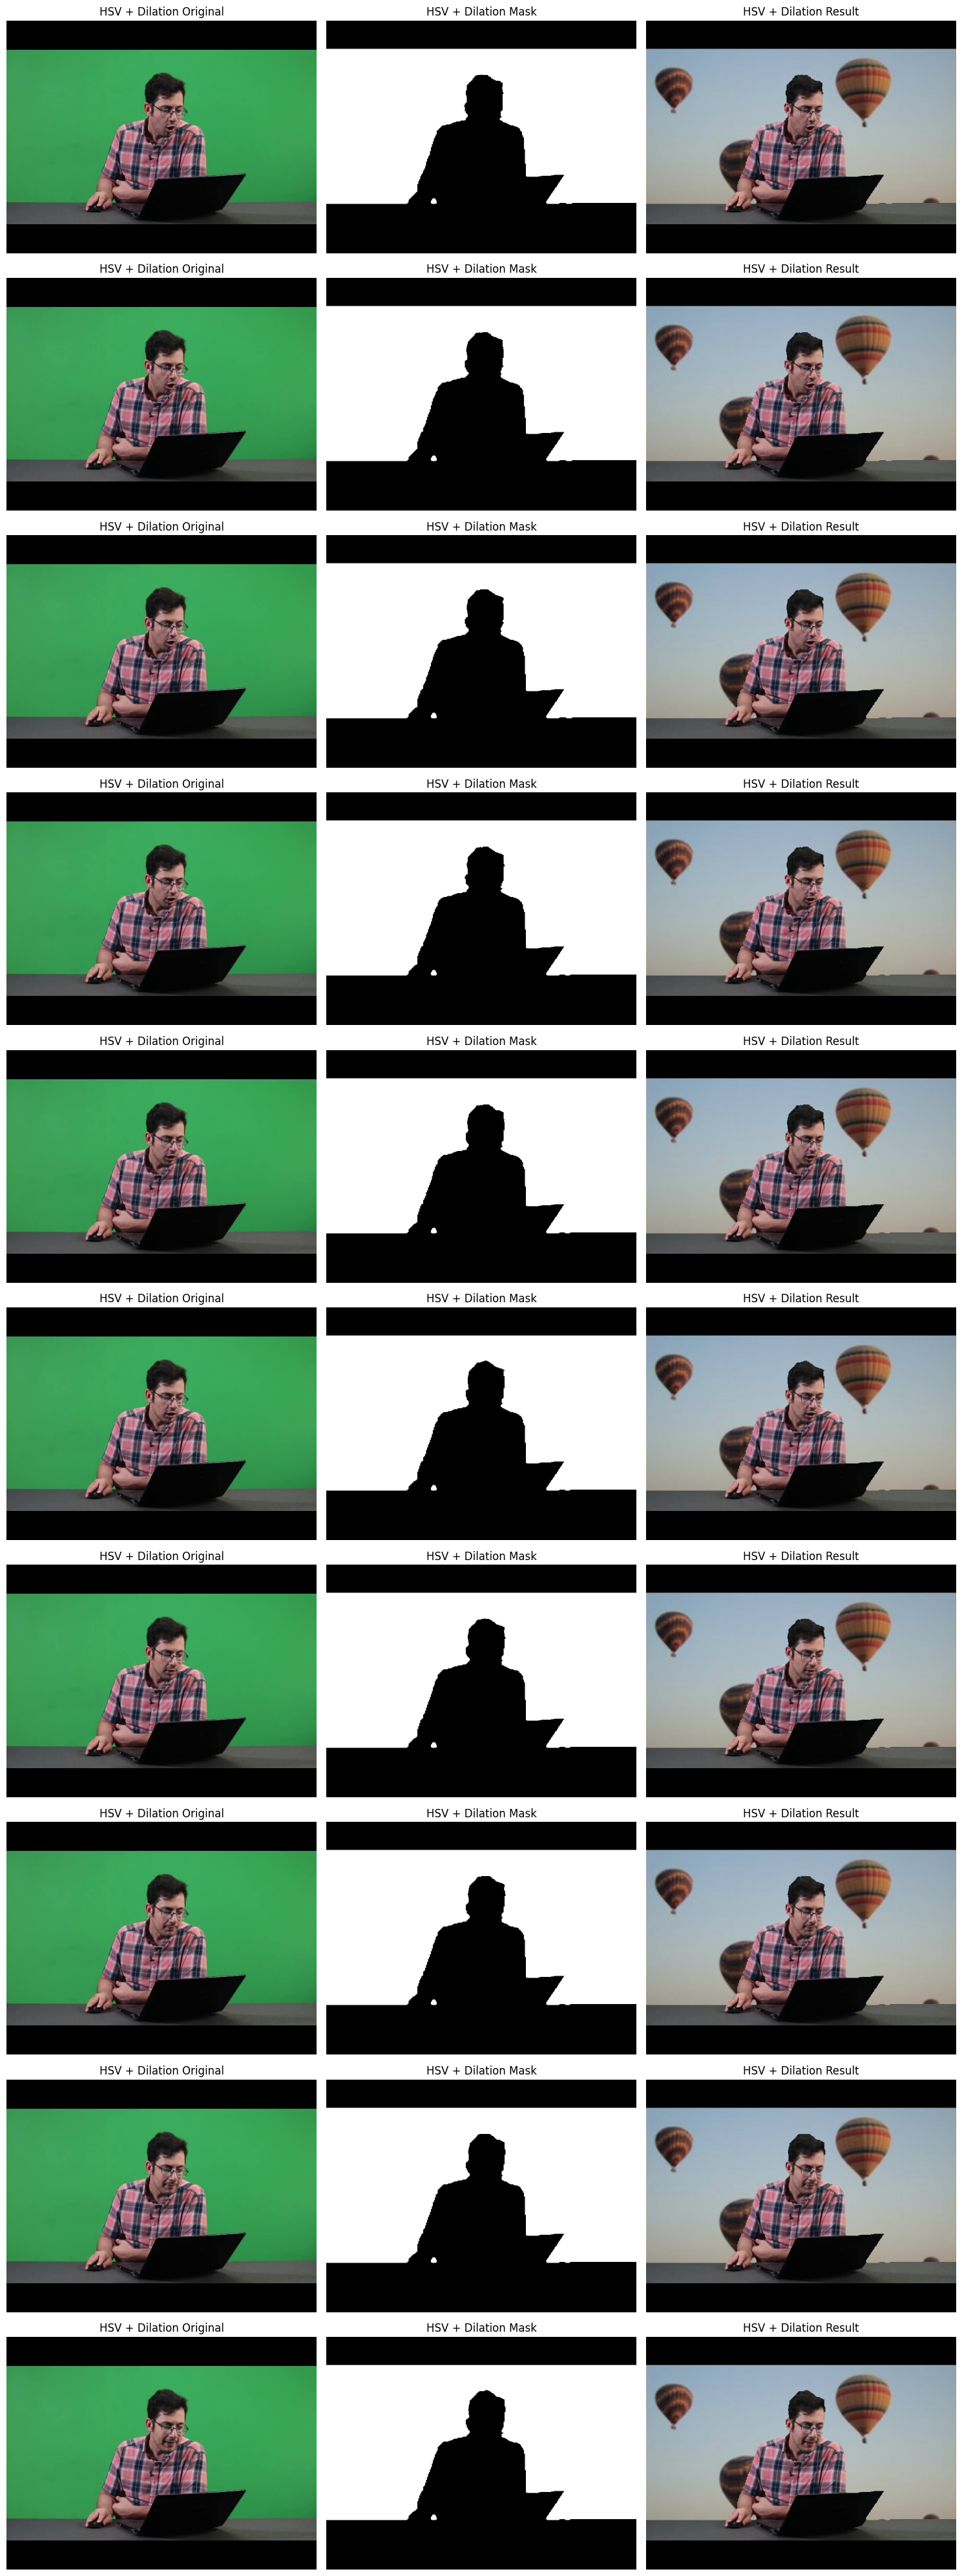

In [ ]:
hsv_dilated_frames, hsv_dilated_samples, _ = process_video_hsv(video_path, bg_image, lower_green, upper_green, dilate=True)

print('HSV + Dilation Processed Frames:', len(hsv_dilated_frames))
show_vide0_samples(hsv_dilated_samples, 'HSV + Dilation')

LAB Processed Frames: 261


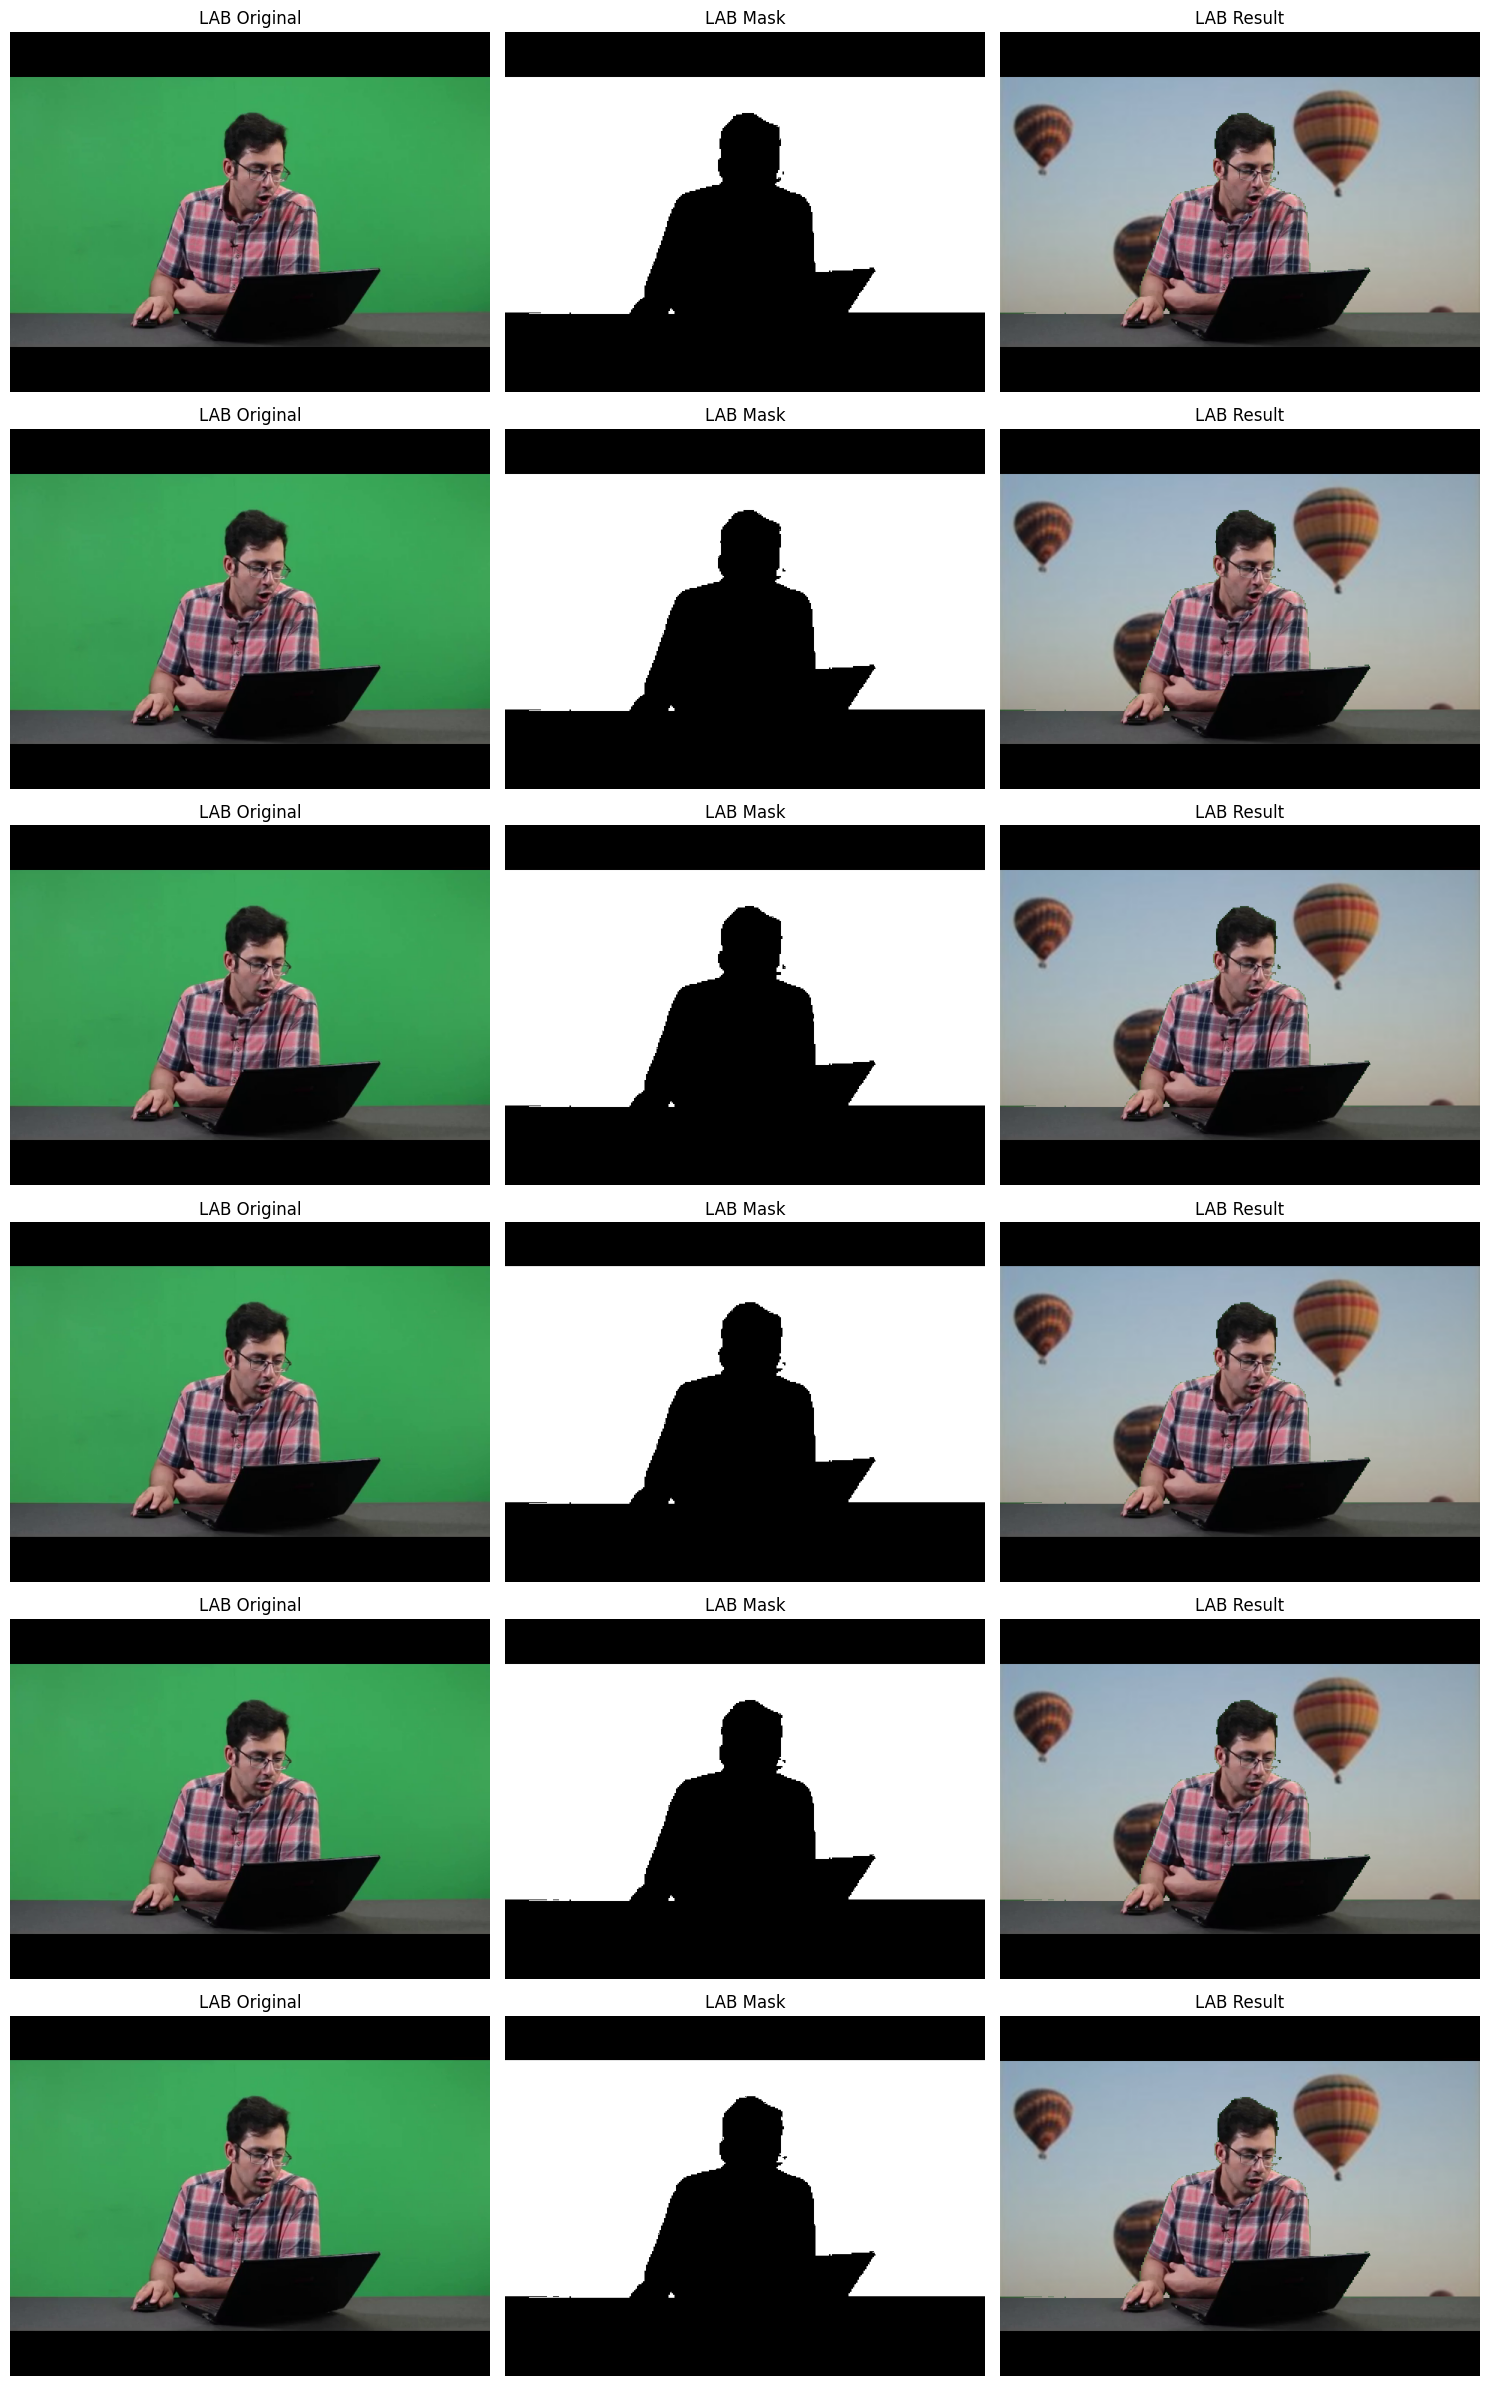

In [13]:
def process_video_lab(video_path, background):
  cap = cv2.VideoCapture(video_path)
  if not cap.isOpened():
    print('Error Opening Video File')

  fps = cap.get(cv2.CAP_PROP_FPS)
  if fps <= 0:
    fps = 20.0

  output_frames = []
  sample_frames = []

  while True:
    ret, frame = cap.read()

    if not ret:
      break

    frame_height, frame_width = frame.shape[:2]
    background = cv2.resize(background, (frame_width, frame_height))

    lab_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)
    a_channel = lab_frame[:, :, 1]
    _, thresh = cv2.threshold(a_channel, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    green_mask = cv2.bitwise_not(thresh)
    new_background = cv2.bitwise_and(background, background, mask=green_mask)
    foreground = cv2.bitwise_and(frame, frame, mask=thresh)

    result = cv2.add(foreground, new_background)

    output_frames.append(result)

    if len(sample_frames) < 6:
      sample_frames.append((frame.copy(), green_mask.copy(), result.copy()))

  cap.release()
  return output_frames, sample_frames, fps

lab_frames, lab_sample_frames, lab_fps = process_video_lab(video_path, bg_image)

print('LAB Processed Frames:', len(lab_frames))
show_vide0_samples(lab_sample_frames, 'LAB')

In [17]:
def save_video(frames, output_path, fps):
  if len(frames) == 0:
    raise ValueError('No Frames Provided')

  height, width = frames[0].shape[:2]
  Writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))

  for frame in frames:
    Writer.write(frame)

  Writer.release()
  print('Video Saved Successfully')

save_video(hsv_frames, 'output_hsv.mp4', video_fps)
save_video(hsv_dilated_frames, 'output_hsv_dilated.mp4', video_fps)
save_video(lab_frames, 'output_lab.mp4', lab_fps)

cv2.imwrite('output_hsv.jpg', hsv_frames[-1])
cv2.imwrite('output_hsv_dilated.jpg', hsv_dilated_frames[-1])
cv2.imwrite('output_lab.jpg', lab_frames[-1])

Video Saved Successfully
Video Saved Successfully
Video Saved Successfully


True